# Vertical Deflection of a Simply Supported Tube under an Off-Centre Point Load

__Benchmark:__ the OpenTURNS use case "Vertical deflection of a tube" (class `DeflectionTube`), OpenTURNS developers (Airbus, EDF, IMACS, ONERA, Phimeca) [[1]][R1][[2]][R2]

__Model:__ the classical Euler–Bernoulli formulas for a simply supported beam with an intermediate point load, from the beam-deflection tables of standard textbooks (Gere and Goodno [[3]][R3]; Budynas and Nisbett, *Shigley's* [[4]][R4]), as cited by OpenTURNS

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds. There is no journal article behind this benchmark: the source is the OpenTURNS documentation page and the textbook formulas it cites.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import tube_model as tm

SEED = 2011                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$F$', r'$L$', r'$a$', r'$D_e$', r'$d_i$', r'$E$']
qoi_labels = {'deflection': 'deflection $v(a)$', 'theta_left': r"left slope $v'(0)$ (rad)",
              'theta_right': r"right slope $v'(L)$ (rad)"}

### Summary

A circular tube of length $L$, outer and inner diameters $D_e$ and $d_i$ and Young's modulus $E$ rests on simple supports and carries a point force $F$ at distance $a$ from the left support; closed-form Euler–Bernoulli beam theory gives the deflection under the load and the slopes at the two supports; all six inputs are random, with the independent normal, uniform and triangular distributions of the input table of the OpenTURNS use case [[1]][R1], and we use the bending second moment $I = \pi(D_e^4 - d_i^4)/64$, so every output is exactly twice the OpenTURNS value (OpenTURNS uses the polar moment, $/32$). We compute the active subspaces of the three outputs from 1000 Monte Carlo samples with exact gradients, scaling every input by its own standard deviation. Each output has a two-dimensional active subspace, with $\lambda_2/\lambda_3$ between 71 and 161, that is spanned almost exactly by the load position $a$ and an "amplitude" direction (the combination of $F$, $D_e$ and $E$ in $F/(EI)$), and a quadratic in the two active variables reproduces the deflection with leave-one-out $R^2 = 0.9975$; the data are this Euler–Bernoulli benchmark as posed, not an accurate prediction for a real tube, because the tube is stubby ($L/D_e \approx 1.9$) and Timoshenko theory puts the shear deflection at about 0.7 times the bending deflection.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

An Euler–Bernoulli beam of length $L$ on simple supports at $x = 0$ and $x = L$ carries a downward point force $F$ at $x = a$; let $b = L - a$ and let $v(x)$ be the deflection, positive upward. The standard results for this load case [[3]][R3][[4]][R4], which are the three outputs of the OpenTURNS use case [[1]][R1], are

$$
v(a) = -\frac{F a^2 b^2}{3 E L I},\qquad
v'(0) = -\frac{F b\,(L^2 - b^2)}{6 E L I},\qquad
v'(L) = \frac{F a\,(L^2 - a^2)}{6 E L I},
$$

the deflection under the load and the slopes (end rotations, in radians) at the left and right supports. For a circular tube the second moment of area about a diameter is

$$
I = \frac{\pi\,(D_e^4 - d_i^4)}{64}.
$$

**A factor of two.** OpenTURNS writes $I = \pi(D_e^4 - d_i^4)/32$ [[1]][R1], which is the *polar* moment of the section, not the bending moment of area; its three outputs are therefore exactly half of the beam-theory values. This notebook uses the textbook $I$ (`tube_model.second_moment`; `openturns_convention=True` reproduces OpenTURNS, checked below). A constant factor scales every eigenvalue by 4 and changes no eigenvector, active variable or $R^2$, so the analysis is the same either way. Both conventions are Euler–Bernoulli values; for how far this stubby tube is from that theory, see *Range of validity* below.

Each output is $F/(E I)$ times a function of $a$ and $L$: $|v(a)| \propto a^2 b^2/L$, largest at $a = L/2$; $|v'(0)| \propto a b (2L - a)/L$ (since $b(L^2-b^2) = ab(2L-a)$), largest at $a = L(1 - 1/\sqrt3) \approx 0.634$; and $v'(L) \propto a b (L + a)/L$, largest at $a = L/\sqrt3 \approx 0.866$.

**Inputs** (independent; distributions from the input table of the OpenTURNS page [[1]][R1]). The page states no units; any consistent set will do (the values, with $E$ = 200 000, read like steel in N/mm² but then $F$ = 1 N on a 1.5 mm tube). The slopes are dimensionless (radians) in any consistent set; the deflection has the length unit. The cell prints the table from `tube_model`, with the exact mean and standard deviation of each distribution (uniform: half-width$/\sqrt3$; symmetric triangular: half-width$/\sqrt6$). The page's API section lists a different, deterministic setting for four inputs (Dirac at $L = 1.5$, $a = 1$, $D_e = 0.8$, $d_i = 0.1$), which is what the `DeflectionTube` class's joint distribution holds; we follow the page's input table, so all six inputs are random, and use the API values only as a reference point.

In [2]:
print(f"{'input':6s} {'distribution':30s} {'mean':>9s} {'sd':>10s}  description")
for j, n in enumerate(tm.NAMES):
    print(f'{n:6s} {tm.DISTRIBUTIONS[j]:30s} {tm.MEAN[j]:9.4g} {tm.SD[j]:10.4g}  {tm.DESCRIPTIONS[j]}')
x_mean = tm.MEAN
x_ot = np.array([1.0, 1.5, 1.0, 0.8, 0.1, 2.0e5])     # the point fixed in OpenTURNS' DeflectionTube class
print('\nat the input means:      ', ', '.join(f'{q} = {v:.6e}' for q, v in zip(tm.QOI_NAMES, tm.outputs(x_mean)[0])))
print('at the OpenTURNS point:  ', ', '.join(f'{q} = {v:.6e}' for q, v in zip(tm.QOI_NAMES, tm.outputs(x_ot)[0])))
print('OpenTURNS convention (I = pi (De^4 - di^4)/32) / this model:',
      np.array2string(tm.outputs(x_ot, openturns_convention=True)[0] / tm.outputs(x_ot)[0], precision=15))
print(f'share of di^4 in De^4 - di^4 at the means: {x_mean[4]**4 / x_mean[3]**4:.2e}')

input  distribution                        mean         sd  description
F      Normal(1, 0.1)                         1        0.1  point force (downward)
L      Normal(1.5, 0.01)                    1.5       0.01  tube length (span between supports)
a      Uniform(0.7, 1.2)                   0.95     0.1443  distance of the force from the left support
De     Triangular(0.75, 0.8, 0.85)          0.8    0.02041  outer diameter of the tube
di     Triangular(0.09, 0.1, 0.11)          0.1   0.004082  inner diameter of the tube
E      Normal(200000, 2000)               2e+05       2000  Young's modulus

at the input means:       deflection = -1.509059e-05, theta_left = -2.960355e-05, theta_right = 3.537986e-05
at the OpenTURNS point:   deflection = -1.381891e-05, theta_left = -2.763781e-05, theta_right = 3.454727e-05
OpenTURNS convention (I = pi (De^4 - di^4)/32) / this model: [0.5 0.5 0.5]
share of di^4 in De^4 - di^4 at the means: 2.44e-04


**Range of validity.** Euler–Bernoulli theory neglects shear deformation and is accurate for slender beams (span at least about ten times the depth); this tube is stubby, with $L/D_e$ below 2. Timoshenko beam theory gives a first estimate of the error. It adds a shear strain $\gamma = V/(\kappa G A)$, with $G = E/(2(1+\nu))$, $A = \pi(D_e^2 - d_i^2)/4$ and a shear coefficient $\kappa$. The beam is statically determinate, so the bending moment and the cross-section rotations are unchanged (the rotations at the supports equal the Euler–Bernoulli slopes), and the shear adds $F a b/(\kappa G A L)$ to the deflection under the load, a fraction
$$
\frac{\delta_{\rm shear}}{|v(a)|} = \frac{3 E I}{\kappa G A\, a b}
$$
of the bending deflection; the centreline slopes at the supports gain $F b/(\kappa G A L)$ and $F a/(\kappa G A L)$, fractions $6EI/(\kappa G A (L^2 - b^2))$ and $6EI/(\kappa G A (L^2 - a^2))$. The benchmark gives no Poisson ratio; we take $\nu = 0.3$ (steel) and Cowper's shear coefficient for a hollow circular section [[6]][R6], $\kappa = 6(1+\nu)(1+m^2)^2/[(7+6\nu)(1+m^2)^2 + (20+12\nu)m^2]$ with $m = d_i/D_e$, and also print the solid-section value $6(1+\nu)/(7+6\nu)$. This is a disclosure only: the model, the data and the analysis below stay Euler–Bernoulli, the benchmark as posed.

In [3]:
nu = 0.3                                              # assumed (steel); the benchmark states no Poisson ratio
def shear_to_bending(X, kappa=None):
    # Timoshenko shear contribution / Euler-Bernoulli bending contribution: deflection under the load, centreline end slopes
    F_, L_, a_, De_, di_, E_ = np.atleast_2d(X).T
    b_ = L_ - a_
    I_, A_, G_ = tm.second_moment(De_, di_), np.pi * (De_**2 - di_**2) / 4, E_ / (2 * (1 + nu))
    m2 = (di_ / De_)**2
    if kappa is None:                                   # Cowper (1966), hollow circular section
        kappa = 6 * (1 + nu) * (1 + m2)**2 / ((7 + 6 * nu) * (1 + m2)**2 + (20 + 12 * nu) * m2)
    k_GA = kappa * G_ * A_
    return kappa, 3 * E_ * I_ / (k_GA * a_ * b_), 6 * E_ * I_ / (k_GA * (L_**2 - b_**2)), 6 * E_ * I_ / (k_GA * (L_**2 - a_**2))
print(f'L/De at the means = {x_mean[1] / x_mean[3]:.3f}')
k_c, r_d, r_l, r_r = shear_to_bending(x_mean)
print(f'Cowper kappa = {k_c[0]:.3f}: shear/bending at the means: deflection {r_d[0]:.3f}, left slope {r_l[0]:.3f}, right slope {r_r[0]:.3f}')
print(f'   Timoshenko / Euler-Bernoulli deflection = {1 + r_d[0]:.3f}; Euler-Bernoulli value short by {1 - 1 / (1 + r_d[0]):.3f}')
k_s, r_d_s, _, _ = shear_to_bending(x_mean, kappa=6 * (1 + nu) / (7 + 6 * nu))
print(f'solid-section kappa = {k_s:.3f}: shear/bending deflection at the means {r_d_s[0]:.3f}')
X_data = np.loadtxt('inputs.csv', delimiter=',')
r_all = shear_to_bending(X_data)[1]
print(f'over the 1000 samples (Cowper kappa): shear/bending deflection from {r_all.min():.3f} to {r_all.max():.3f}, median {np.median(r_all):.3f}')

L/De at the means = 1.875
Cowper kappa = 0.852: shear/bending at the means: deflection 0.712, left slope 0.382, right slope 0.552
   Timoshenko / Euler-Bernoulli deflection = 1.712; Euler-Bernoulli value short by 0.416
solid-section kappa = 0.886: shear/bending deflection at the means 0.684
over the 1000 samples (Cowper kappa): shear/bending deflection from 0.590 to 1.142, median 0.718


At the input means $L/D_e = 1.875$, and with Cowper's $\kappa = 0.852$ shear adds 0.712 times the bending deflection under the load (0.684 with the solid-section $\kappa = 0.886$): a shear-deformable tube deflects 1.712 times the Euler–Bernoulli value, which is therefore short by 0.416. Over the 1000 samples the fraction runs from 0.590 to 1.142 (median 0.718), largest when the load is near a support; the centreline slopes gain 0.382 (left) and 0.552 (right) of their bending values at the means. Even Timoshenko theory is only an estimate at so small a span-to-depth ratio, so the outputs here, like the OpenTURNS ones, are a test function with the product structure of beam theory and not a physically accurate tube prediction; the factor of two between the OpenTURNS and textbook $I$ is a departure of the same order.

### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples (not Latin hypercube) of the six inputs (`numpy.random.default_rng(2011)`) and wrote the physical inputs, the three outputs and their exact gradients with respect to the physical inputs (hand-derived from the logarithmic derivatives; see `DATA.md`).

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 6) physical inputs F, L, a, De, di, E
F = np.loadtxt('outputs.csv', delimiter=',')       # (M, 3) deflection, theta_left, theta_right
D = np.loadtxt('gradients.csv', delimiter=',')     # (M, 18) physical gradients, 6 columns per QoI
G = D.reshape(-1, 3, 6)                            # G[:, q, j] = d QoI_q / d x_j
M, m = X.shape
print(f'inputs {X.shape}, outputs {F.shape}, gradients {D.shape} -> {G.shape}')

inputs (1000, 6), outputs (1000, 3), gradients (1000, 18) -> (1000, 3, 6)


We check the files against the model, the gradients against central finite differences (an independent computation, relative step $10^{-6}$ per input), and the closed forms against the unit-load (virtual-work) method by numerical quadrature of the bending moment, which does not use the tabulated formulas. We also check the sample against the stated distributions and count samples outside the physical domain.

In [5]:
print(f'max |model - file| / |file|: {np.max(np.abs(tm.outputs(X) / F - 1)):.1e}')
fd = np.empty_like(G)
for j in range(m):
    h = 1e-6 * np.abs(X[:, j])
    Xp, Xm = X.copy(), X.copy()
    Xp[:, j] += h
    Xm[:, j] -= h
    fd[:, :, j] = (tm.outputs(Xp) - tm.outputs(Xm)) / (2 * h[:, None])
err = np.linalg.norm(fd - G, axis=2) / np.linalg.norm(G, axis=2)
print('gradients vs central differences (relative step 1e-6), max relative error (row 2-norm):',
      ', '.join(f'{q} {e:.1e}' for q, e in zip(tm.QOI_NAMES, err.max(axis=0))))
V = np.array([tm.virtual_work(x) for x in X[:50]])
print(f'closed forms vs unit-load quadrature at the first 50 samples, max relative difference: {np.max(np.abs(V / F[:50] - 1)):.1e}')
print('sample means / exact means:', np.round(X.mean(axis=0) / tm.MEAN, 4))
print('sample sds / exact sds:   ', np.round(X.std(axis=0, ddof=1) / tm.SD, 3))
print(f'ranges: a [{X[:, 2].min():.4f}, {X[:, 2].max():.4f}], L [{X[:, 1].min():.4f}, {X[:, 1].max():.4f}], '
      f'F [{X[:, 0].min():.3f}, {X[:, 0].max():.3f}], min (L - a) = {np.min(X[:, 1] - X[:, 2]):.4f}')
print(f'samples outside the physical domain: F <= 0: {np.sum(X[:, 0] <= 0)}, a >= L: {np.sum(X[:, 2] >= X[:, 1])}, '
      f'di >= De: {np.sum(X[:, 4] >= X[:, 3])}, E <= 0: {np.sum(X[:, 5] <= 0)}; duplicate rows: {M - len(np.unique(X, axis=0))}')
print(f'samples with a < L/2 (deflection still rising with a): {np.sum(X[:, 2] < X[:, 1] / 2)}; '
      f'with a < L/sqrt(3) (right slope still rising): {np.sum(X[:, 2] < X[:, 1] / np.sqrt(3))}')

max |model - file| / |file|: 0.0e+00
gradients vs central differences (relative step 1e-6), max relative error (row 2-norm): deflection 5.1e-10, theta_left 4.9e-10, theta_right 5.0e-10
closed forms vs unit-load quadrature at the first 50 samples, max relative difference: 6.7e-16
sample means / exact means: [1.0006 1.     1.0003 0.9997 1.0009 0.9997]
sample sds / exact sds:    [0.999 0.964 1.01  0.997 0.998 0.977]
ranges: a [0.7005, 1.1996], L [1.4693, 1.5322], F [0.683, 1.277], min (L - a) = 0.2885
samples outside the physical domain: F <= 0: 0, a >= L: 0, di >= De: 0, E <= 0: 0; duplicate rows: 0
samples with a < L/2 (deflection still rising with a): 98; with a < L/sqrt(3) (right slope still rising): 338


The files match the model exactly, the gradients agree with central differences to $5.1\times10^{-10}$ (deflection), $4.9\times10^{-10}$ (left slope) and $5.0\times10^{-10}$ (right slope), the size of the differencing error, and the closed forms agree with the unit-load quadrature to $6.7\times10^{-16}$ at the first 50 samples. Sample means are within 0.1 % of the exact means and sample standard deviations within 3.6 % of the exact ones (the largest departure, 0.964, is for $L$). No sample is outside the physical domain: $F$ stays in $[0.683, 1.277]$, and the load is always inside the span (smallest $L - a$ = 0.2885), so none is dropped; there are no duplicate rows. 98 samples have $a < L/2$, where the deflection is still growing in magnitude with $a$, and 338 have $a < L/\sqrt3$, where the right slope is.

### Estimate the subspace

The model is closed form, so we have exact gradients and use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ in normalized coordinates; $M = 1000$ is above $10m = 60$ and above 300. We use 500 bootstrap replicates and orient each eigenvector so that its active variable has a nonnegative sample covariance with the QoI (`ac.orient(by="covariance")`).

**Scaling.** The inputs have three kinds of distribution, and active_subspaces v1 offers only uniform and Gaussian spaces. We scale **every** input by its own standard deviation, $z_j = (x_j - \mu_j)/\sigma_j$, by passing `ac.Gaussian(mean, sd**2)` as the space: the library uses it only to standardize (physical $\mathbf X$ and physical gradients go in, and the normalized gradient is $\sigma_j\,\partial f/\partial x_j$). The samples come from the true normal, uniform and triangular distributions, so $\hat{\mathbf C}$ estimates $\mathbf C$ under the true joint density in these coordinates. Mixing the uniform's half-range with the others' standard deviations would weight $a$ by $\sqrt3$ more and is avoided.

**Dimension.** We set $n = 2$ by hand for all three outputs. The library's eigenvalue-gap rule (`"evg"`) measures absolute gaps and picks $n = 1$, but the ratio $\lambda_2/\lambda_3$ is much larger than $\lambda_1/\lambda_2$ for every output (printed below), the bootstrap subspace error at $k = 2$ is small for every output (at most 0.0035), and the second direction has a clear physical meaning (see the eigenvectors).

In [6]:
space = ac.Gaussian(tm.MEAN, tm.SD**2, names=list(tm.NAMES))   # used only to standardize: (x - mean)/sd
subs = {}
for q, name in enumerate(tm.QOI_NAMES):
    s = ac.active_subspace(space=space, X=X, f=F[:, q], grads=G[:, q], estimator='as', n=2, nboot=500, rng=SEED)
    subs[name] = ac.orient(s, by='covariance', X=X, f=F[:, q])
    lam = subs[name].eigenvalues
    _, _, k_evg = ac.dimension_criterion(subs[name], rule='evg')
    print(f'{name}: eigenvalues {np.array2string(lam, precision=3)}')
    print(f'   ratios lambda_k/lambda_k+1: {np.array2string(lam[:-1] / lam[1:], precision=1)}; '
          f'"evg" rule picks n = {k_evg}; share of the trace in the first two: {lam[:2].sum() / lam.sum():.5f}')
sub = subs['deflection']
lam = sub.eigenvalues

deflection: eigenvalues [1.553e-11 1.882e-12 1.166e-14 2.288e-16 1.155e-17 6.224e-21]
   ratios lambda_k/lambda_k+1: [   8.3  161.3   51.    19.8 1856.1]; "evg" rule picks n = 1; share of the trace in the first two: 0.99932


theta_left: eigenvalues [4.620e-11 3.292e-12 4.646e-14 2.656e-16 4.070e-17 2.499e-20]
   ratios lambda_k/lambda_k+1: [  14.    70.9  175.     6.5 1628.7]; "evg" rule picks n = 1; share of the trace in the first two: 0.99906


theta_right: eigenvalues [3.090e-11 9.951e-12 6.309e-14 5.463e-16 5.966e-17 3.331e-20]
   ratios lambda_k/lambda_k+1: [   3.1  157.7  115.5    9.2 1790.9]; "evg" rule picks n = 1; share of the trace in the first two: 0.99844


### Results: the deflection under the load

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

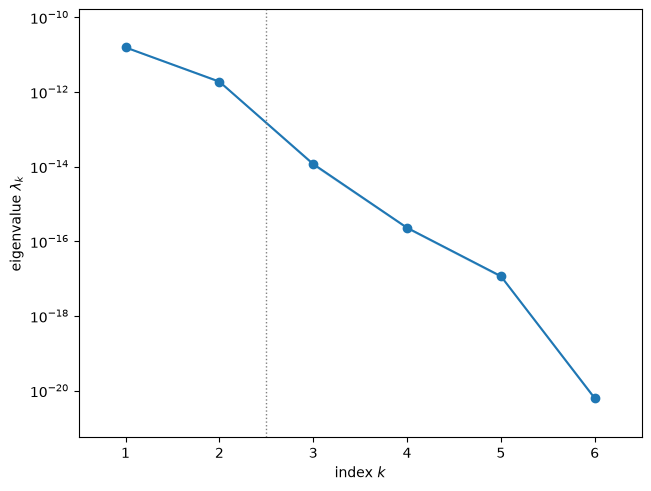

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The eigenvalues are $1.553\times10^{-11}$, $1.882\times10^{-12}$, $1.166\times10^{-14}$, $2.288\times10^{-16}$, $1.155\times10^{-17}$ and $6.224\times10^{-21}$ (their scale follows from deflections of order $10^{-5}$), so $\lambda_1/\lambda_2 = 8.3$ and $\lambda_2/\lambda_3 = 161.3$, and the first two hold 99.932 % of the trace. The last ratio, $\lambda_5/\lambda_6 = 1856$, isolates the inner diameter: $d_i^4$ is only $2.4\times10^{-4}$ of $D_e^4$, so $d_i$ is almost inert.

bootstrap mean subspace distance, k = 1..5: [0.0069 0.0025 0.004  0.0062 0.0007]


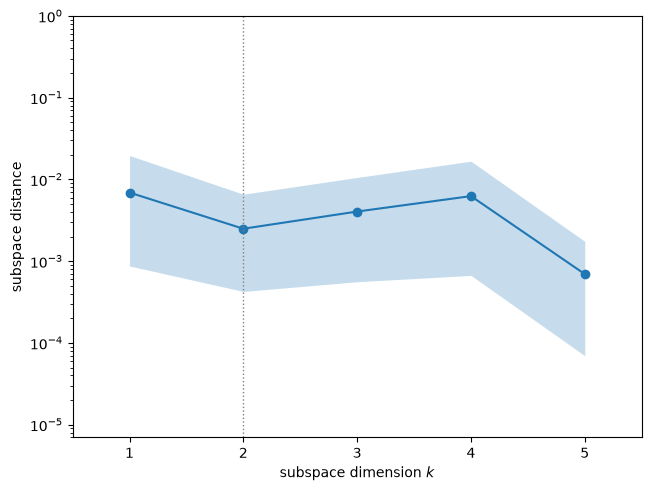

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:', np.array2string(sub.bootstrap_distances.mean(axis=0), precision=4))
fig

The bootstrap mean subspace distance is 0.0069 for $k = 1$ and 0.0025 for $k = 2$, so the two-dimensional subspace is estimated more stably than its first direction alone; it is 0.0040, 0.0062 and 0.0007 for $k = 3, 4, 5$ (the last is the complement of the nearly inert $d_i$).

t_amp: F +0.698, L +0.000, a +0.000, De -0.713, di +0.000, E -0.070
w1: F -0.302, L -0.105, a +0.894, De +0.313, di -0.000, E +0.030
w2: F -0.623, L -0.095, a -0.445, De +0.633, di -0.000, E +0.062
norm of the projection onto span(w1, w2): t_amp 0.9913, e_a 0.9987


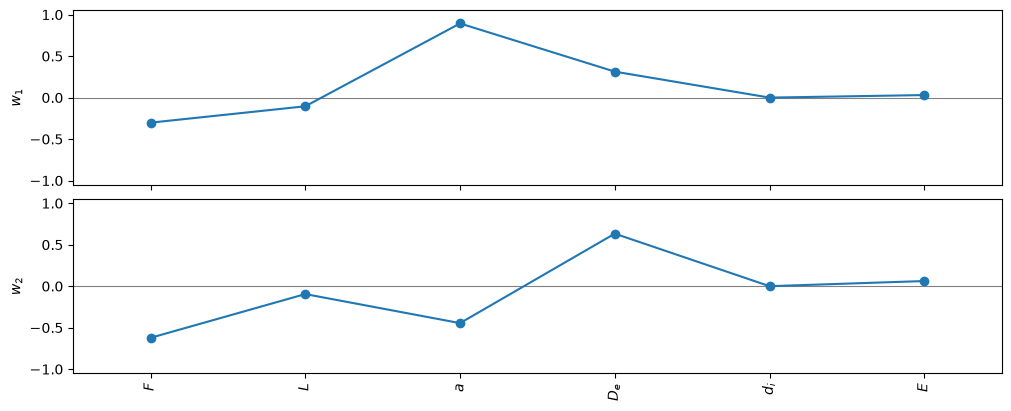

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(10, 4))
plt.close(fig)
W = sub.W
# 'amplitude' direction: the standardized gradient of ln F - ln E - ln I at the means (the factor F/(E I))
t_amp = tm.SD * np.array([1 / tm.MEAN[0], 0, 0, -4 * tm.MEAN[3]**3 / (tm.MEAN[3]**4 - tm.MEAN[4]**4),
                          4 * tm.MEAN[4]**3 / (tm.MEAN[3]**4 - tm.MEAN[4]**4), -1 / tm.MEAN[5]])
t_amp /= np.linalg.norm(t_amp)
e_a = np.eye(m)[2]
print('t_amp:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(tm.NAMES, t_amp)))
for k in (0, 1):
    print(f'w{k + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(tm.NAMES, W[:, k])))
P = W[:, :2] @ W[:, :2].T
print(f'norm of the projection onto span(w1, w2): t_amp {np.linalg.norm(P @ t_amp):.4f}, e_a {np.linalg.norm(P @ e_a):.4f}')
fig

In the order $F, L, a, D_e, d_i, E$, $\mathbf w_1 = (-0.302, -0.105, +0.894, +0.313, -0.000, +0.030)$ and $\mathbf w_2 = (-0.623, -0.095, -0.445, +0.633, -0.000, +0.062)$. Neither is a single physical effect, but their span is: it contains the load-position direction $\mathbf e_a$ almost exactly (projection norm 0.9987) and the **amplitude** direction $\mathbf t$, the standardized gradient of $\ln F - \ln E - \ln I$ at the means, $\mathbf t = (+0.698, 0, 0, -0.713, +0.000, -0.070)$, nearly as well (0.9913). $F$ and $D_e$ carry equal weight in $\mathbf t$ because the coefficient of variation of $F$ (0.1) equals four times that of $D_e$ ($4 \times 0.0255 = 0.102$; $I \propto D_e^4$), while $E$ (0.01) and $L$ (0.0067) vary too little to matter and $d_i$ is inert. So the deflection is, to a very good approximation, a function of *where the load is* and *how large $F/(EI)$ is*, which is its product form.

y1 range [-2.28, 2.19]; corr(y1, a) = 0.8984; corr(y2, a) = -0.4809
largest downward deflection -2.473e-05 at a = 0.785 (L/2 = 0.744), F = 1.181; smallest |deflection| 5.777e-06; ratio of extremes 4.28


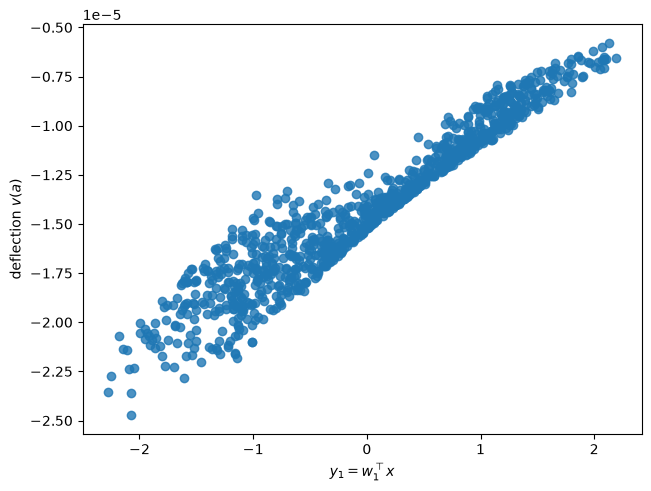

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 0], dims=1, qoi_label=qoi_labels['deflection'])
plt.close(fig)
Y = space.to_normalized(X) @ W[:, :2]
print(f'y1 range [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(y1, a) = {np.corrcoef(Y[:, 0], X[:, 2])[0, 1]:.4f}; '
      f'corr(y2, a) = {np.corrcoef(Y[:, 1], X[:, 2])[0, 1]:.4f}')
i_min = np.argmin(F[:, 0])
print(f'largest downward deflection {F[i_min, 0]:.3e} at a = {X[i_min, 2]:.3f} (L/2 = {X[i_min, 1] / 2:.3f}), F = {X[i_min, 0]:.3f}; '
      f'smallest |deflection| {np.abs(F[:, 0]).min():.3e}; ratio of extremes {F[:, 0].min() / F[:, 0].max():.2f}')
fig

corr(y2, F/(E I)) = -0.8835; corr(y1, F/(E I)) = -0.3954


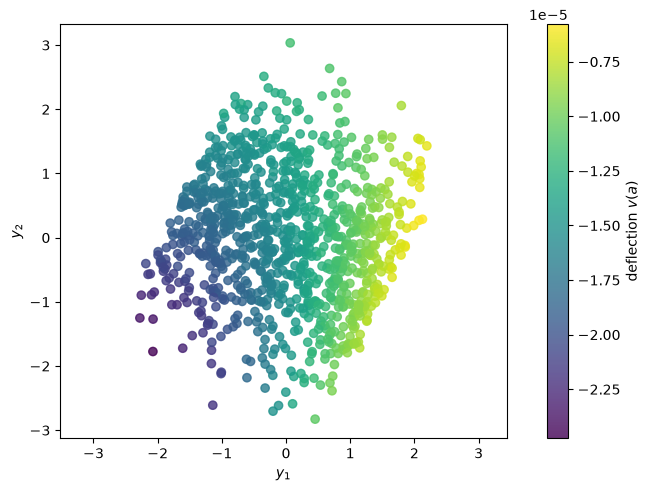

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 0], dims=2, qoi_label=qoi_labels['deflection'])
plt.close(fig)
amp = X[:, 0] / (X[:, 5] * tm.second_moment(X[:, 3], X[:, 4]))
print(f'corr(y2, F/(E I)) = {np.corrcoef(Y[:, 1], amp)[0, 1]:.4f}; corr(y1, F/(E I)) = {np.corrcoef(Y[:, 0], amp)[0, 1]:.4f}')
fig

The first active variable spans $[-2.28, 2.19]$ and has correlation 0.8984 with $a$. Moving along $+y_1$ (mostly larger $a$) the deflection gets smaller in magnitude, because $a^2b^2$ falls as the load moves from mid-span toward the right support; the largest downward deflection, $-2.473\times10^{-5}$, is at $a = 0.785$, close to mid-span ($L/2 = 0.744$ there), with a large force ($F = 1.181$), and the extremes differ by a factor 4.28. The vertical scatter in the one-dimensional plot is the amplitude: in the two-dimensional plot the colour changes along $y_2$ as well, and $y_2$ has correlation $-0.8835$ with $F/(EI)$ (and $y_1$ $-0.3954$).

### Results: the end slopes

The same estimator, scaling and $n = 2$ for the left and right slopes. The cell prints their leading eigenvectors, how well their two-dimensional subspaces contain $\mathbf t$ and $\mathbf e_a$, and their distance from the deflection's subspace, and draws one- and two-dimensional sufficient summary plots (left slope on top).

theta_left:
   w1: F -0.406, L -0.093, a +0.805, De +0.420, di -0.000, E +0.041
   w2: F +0.570, L +0.030, a +0.591, De -0.568, di +0.000, E -0.055
   projection norms onto span(w1, w2): t_amp 0.9968, e_a 0.9983; distance to the deflection subspace (2-norm of P - P_defl): 0.0534
   bootstrap mean subspace distance, k = 1..5: [0.0067 0.0035 0.0024 0.0117 0.0008]
theta_right:
   w1: F +0.575, L +0.106, a -0.548, De -0.595, di +0.000, E -0.058
   w2: F +0.386, L +0.010, a +0.835, De -0.390, di +0.000, E -0.038
   projection norms onto span(w1, w2): t_amp 0.9955, e_a 0.9987; distance to the deflection subspace (2-norm of P - P_defl): 0.0380
   bootstrap mean subspace distance, k = 1..5: [0.0188 0.0025 0.0027 0.0093 0.0007]


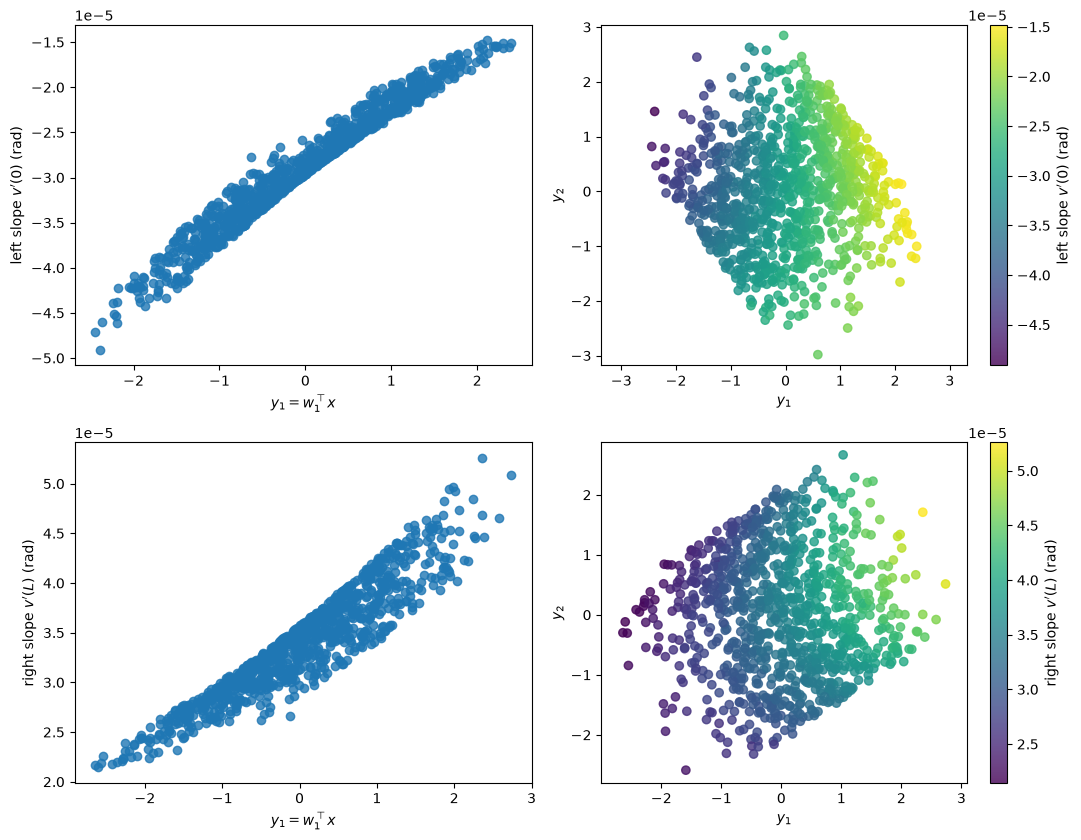

In [12]:
for name in ('theta_left', 'theta_right'):
    s = subs[name]
    print(f'{name}:')
    for k in (0, 1):
        print(f'   w{k + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(tm.NAMES, s.W[:, k])))
    Ps = s.W[:, :2] @ s.W[:, :2].T
    print(f'   projection norms onto span(w1, w2): t_amp {np.linalg.norm(Ps @ t_amp):.4f}, e_a {np.linalg.norm(Ps @ e_a):.4f}; '
          f'distance to the deflection subspace (2-norm of P - P_defl): {np.linalg.norm(Ps - P, 2):.4f}')
    print('   bootstrap mean subspace distance, k = 1..5:', np.array2string(s.bootstrap_distances.mean(axis=0), precision=4))
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for r, name in enumerate(('theta_left', 'theta_right')):
    q = tm.QOI_NAMES.index(name)
    ac.plotting.plot_sufficient_summary(subs[name], X=X, f=F[:, q], dims=1, qoi_label=qoi_labels[name], ax=axes[r, 0])
    ac.plotting.plot_sufficient_summary(subs[name], X=X, f=F[:, q], dims=2, qoi_label=qoi_labels[name], ax=axes[r, 1])
fig.tight_layout()
plt.close(fig)
fig

For the left slope the eigenvalue ratios are $\lambda_1/\lambda_2 = 14.0$ and $\lambda_2/\lambda_3 = 70.9$ (99.906 % of the trace in two), and for the right slope $3.1$ and $157.7$ (99.844 %). Both two-dimensional subspaces contain the amplitude direction (projection norms 0.9968 and 0.9955) and the load position (0.9983 and 0.9987), and they are within 0.0534 (left) and 0.0380 (right) of the deflection's subspace, so the three outputs share one active subspace up to a rotation inside it. The order of $\lambda_1/\lambda_2$ follows the shape in $a$: over $a \in [0.7, 1.2]$ the left slope's magnitude decreases monotonically (its maximum is at $a \approx 0.634$, outside the range), so $a$ dominates and $\mathbf w_1$ has $a$-weight 0.805; the right slope peaks inside the range ($a \approx 0.866$; 338 samples lie below it), so its response to $a$ folds back, the $a$-part of the gradient averages out and the amplitude takes the lead ($\mathbf w_1$: $F$ +0.575, $D_e$ −0.595, $a$ −0.548). In the right-slope plots the fold shows as scatter that widens toward large $y_1$, and its first direction is the least stable (bootstrap distance 0.0188 for $k = 1$, against 0.0025 for $k = 2$).

### Surrogates on the active variables

Polynomials (degree 2 and 3) in one and in two active variables for each output, with leave-one-out $R^2$; the figure shows the quadratic in $(y_1, y_2)$ for the deflection.

deflection   degree 2 in 1 active variable(s): LOO R^2 = 0.9201
deflection   degree 3 in 1 active variable(s): LOO R^2 = 0.9200
deflection   degree 2 in 2 active variable(s): LOO R^2 = 0.9975
deflection   degree 3 in 2 active variable(s): LOO R^2 = 0.9993
theta_left   degree 2 in 1 active variable(s): LOO R^2 = 0.9664
theta_left   degree 3 in 1 active variable(s): LOO R^2 = 0.9664
theta_left   degree 2 in 2 active variable(s): LOO R^2 = 0.9986
theta_left   degree 3 in 2 active variable(s): LOO R^2 = 0.9991
theta_right  degree 2 in 1 active variable(s): LOO R^2 = 0.8737
theta_right  degree 3 in 1 active variable(s): LOO R^2 = 0.8734
theta_right  degree 2 in 2 active variable(s): LOO R^2 = 0.9966
theta_right  degree 3 in 2 active variable(s): LOO R^2 = 0.9981


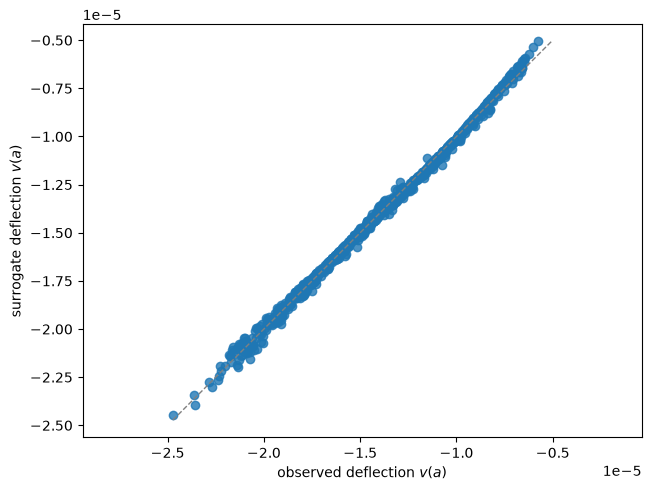

In [13]:
loo = {}
for q, name in enumerate(tm.QOI_NAMES):
    s1 = ac.active_subspace(space=space, X=X, f=F[:, q], grads=G[:, q], estimator='as', n=1)   # same eigenvectors, n = 1
    for n_, s_ in ((1, s1), (2, subs[name])):
        for deg in (2, 3):
            loo[name, n_, deg] = ac.fit_surrogate(X=X, f=F[:, q], subspace=s_, kind='poly', degree=deg)
            print(f'{name:12s} degree {deg} in {n_} active variable(s): LOO R^2 = {loo[name, n_, deg].loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(loo['deflection', 2, 2], X=X, f=F[:, 0], qoi_label=qoi_labels['deflection'])
plt.close(fig)
fig

With one active variable the leave-one-out $R^2$ is 0.9201 (deflection), 0.9664 (left slope) and 0.8737 (right slope) for quadratics, and cubics do no better (0.9200, 0.9664, 0.8734): what is missing is the second direction, not polynomial degree. With two active variables the quadratics reach 0.9975, 0.9986 and 0.9966 and the cubics 0.9993, 0.9991 and 0.9981. A six-input model is thus replaced by a quadratic in two variables with relative misfit of a few tenths of a percent of the variance.

### Comparison with the source

The OpenTURNS page gives the model and the distributions but no numerical results (no moments, Sobol' indices or subspace). For reference the cell computes the means and standard deviations of the three outputs from $10^6$ fresh Monte Carlo samples (seed drawn from `SEED`), with 95 % intervals, and the outputs at the API's fixed point in both conventions for $I$.

In [14]:
rng = np.random.default_rng(SEED)
Xmc = tm.sample(10**6, rng.integers(2**63))
Fmc = tm.outputs(Xmc)
for q, name in enumerate(tm.QOI_NAMES):
    f = Fmc[:, q]
    se_m = f.std(ddof=1) / np.sqrt(len(f))
    se_s = np.sqrt((np.mean((f - f.mean())**4) - f.var()**2) / len(f)) / (2 * f.std())
    print(f'{name:12s} 1e6 Monte Carlo samples: mean {f.mean():.5e} +- {1.96 * se_m:.1e}, sd {f.std(ddof=1):.4e} +- {1.96 * se_s:.1e} (95 %); '
          f'the 1000 in the files: mean {F[:, q].mean():.5e}, sd {F[:, q].std(ddof=1):.4e}')
    g = F[:, q]                                     # the 1000-sample values in units of their own standard errors
    se_m1 = g.std(ddof=1) / np.sqrt(len(g))
    se_s1 = np.sqrt((np.mean((g - g.mean())**4) - g.var()**2) / len(g)) / (2 * g.std())
    print(f'{"":12s} (1000-sample value - 1e6-sample value) / its standard error: mean {(g.mean() - f.mean()) / se_m1:+.2f}, '
          f'sd {(g.std(ddof=1) - f.std(ddof=1)) / se_s1:+.2f}')
print('OpenTURNS convention at its fixed point (half the values of this model):',
      ', '.join(f'{q} = {v:.6e}' for q, v in zip(tm.QOI_NAMES, tm.outputs(x_ot, openturns_convention=True)[0])))

deflection   1e6 Monte Carlo samples: mean -1.42113e-05 +- 7.6e-09, sd 3.8821e-06 +- 4.5e-09 (95 %); the 1000 in the files: mean -1.41955e-05, sd 3.8303e-06
             (1000-sample value - 1e6-sample value) / its standard error: mean +0.13, sd -0.77
theta_left   1e6 Monte Carlo samples: mean -2.88459e-05 +- 1.3e-08, sd 6.8184e-06 +- 8.5e-09 (95 %); the 1000 in the files: mean -2.88415e-05, sd 6.6879e-06
             (1000-sample value - 1e6-sample value) / its standard error: mean +0.02, sd -1.05


theta_right  1e6 Monte Carlo samples: mean 3.39653e-05 +- 1.1e-08, sd 5.5311e-06 +- 7.6e-09 (95 %); the 1000 in the files: mean 3.39727e-05, sd 5.3523e-06
             (1000-sample value - 1e6-sample value) / its standard error: mean +0.04, sd -1.56
OpenTURNS convention at its fixed point (half the values of this model): deflection = -6.909454e-06, theta_left = -1.381891e-05, theta_right = 1.727363e-05


| Quantity | OpenTURNS / textbook value | Notebook value |
|---|---|---|
| Formulas for $v(a)$, $v'(0)$, $v'(L)$ | as printed in [1], [3], [4] | same; checked against unit-load quadrature to $6.7\times10^{-16}$ |
| Second moment of area $I$ | $\pi(D_e^4-d_i^4)/32$ [1]; $\pi(D_e^4-d_i^4)/64$ in beam theory [3], [4] | $/64$; OpenTURNS outputs are exactly 0.5 times ours |
| Outputs at $F = 1$, $L = 1.5$, $a = 1$, $D_e = 0.8$, $d_i = 0.1$, $E = 2\times10^5$ | not reported | $v(a) = -1.381891\times10^{-5}$, $v'(0) = -2.763781\times10^{-5}$, $v'(L) = 3.454727\times10^{-5}$ (OpenTURNS convention: half) |
| Mean and sd of $v(a)$ | not reported | $-1.42113\times10^{-5} \pm 7.6\times10^{-9}$; $3.8821\times10^{-6} \pm 4.5\times10^{-9}$ ($10^6$ samples) |
| Mean and sd of $v'(0)$ | not reported | $-2.88459\times10^{-5} \pm 1.3\times10^{-8}$; $6.8184\times10^{-6} \pm 8.5\times10^{-9}$ |
| Mean and sd of $v'(L)$ | not reported | $3.39653\times10^{-5} \pm 1.1\times10^{-8}$; $5.5311\times10^{-6} \pm 7.6\times10^{-9}$ |
| Shear deflection (Timoshenko, $\nu = 0.3$) / bending deflection at the means | not discussed ($L/D_e = 1.875$) | 0.712 (Cowper $\kappa$); the data stay Euler–Bernoulli |
| Active subspace | not reported | $n = 2$ for all three; $\lambda_1/\lambda_2 = 8.3, 14.0, 3.1$ and $\lambda_2/\lambda_3 = 161.3, 70.9, 157.7$ (deflection, left, right slope) |

The 1000 samples in the files give means and standard deviations within 1.6 of their own standard errors of the $10^6$-sample values (the largest departure is $-1.56$ standard errors, for the sd of the right slope; deflection: $-1.41955\times10^{-5}$ and $3.8303\times10^{-6}$, at $+0.13$ and $-0.77$).

### References

[1] OpenTURNS. "Use case: vertical deflection of a tube" (class `DeflectionTube`), OpenTURNS 1.22 documentation, © 2005–2023 Airbus-EDF-IMACS-ONERA-Phimeca, <https://openturns.github.io/openturns/1.22/usecases/use_case_deflection_tube.html> (accessed 2026-10-31).

[2] M. Baudin, A. Dutfoy, B. Iooss, and A.-L. Popelin. [OpenTURNS: An industrial software for uncertainty quantification in simulation](https://doi.org/10.1007/978-3-319-12385-1_64). In *Handbook of Uncertainty Quantification*, pages 2001–2038. Springer, Cham, 2017.

[3] J. M. Gere and B. J. Goodno. *Mechanics of Materials*, 7th edition. Cengage Learning, 2009. (Cited by [1] for the formulas; not opened for this notebook.)

[4] R. G. Budynas and J. K. Nisbett. *Shigley's Mechanical Engineering Design*, 9th edition. McGraw-Hill, 2011. (Cited by [1] for the formulas; not opened for this notebook.)

[5] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[6] G. R. Cowper. [The shear coefficient in Timoshenko's beam theory](https://doi.org/10.1115/1.3625046). *Journal of Applied Mechanics*, 33(2):335–340, 1966.

[R1]: https://openturns.github.io/openturns/1.22/usecases/use_case_deflection_tube.html
[R2]: https://doi.org/10.1007/978-3-319-12385-1_64
[R3]: #References
[R4]: #References
[R6]: https://doi.org/10.1115/1.3625046

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 3.4 s
